In [1]:
import pandas as pd

In [2]:
embed = pd.read_csv("data/oag_wzx_wzy_dedup_all_layers_embeddings.csv")
embed = embed[~embed.id.str.contains("novel", na=False)]

In [3]:
short = pd.read_csv("data/short_proteins.csv")
exclude = pd.read_csv("data/exclusion list.csv")



In [4]:
embed = embed[~embed.id.isin(short.id)]


In [5]:
embed = embed[~embed.id.isin(exclude.protein_id)]
#embed.to_csv("oag_embed_pruned.csv", index=False)

In [6]:
def filter_layer(embed: pd.DataFrame, layer: int) -> pd.DataFrame:
    """Return the dataframe restricted to the mean-pooled embeddings of one layer."""
    cols = ["id"] + [c for c in embed.columns if c.startswith(f"layer{layer}_dim_")]
    return embed[cols]

# e.g. filter_layer(embed, 0)

In [7]:
embed36 = filter_layer(embed,15)


In [8]:
from sklearn.preprocessing import StandardScaler
import umap
import matplotlib.pyplot as plt
X = embed36.select_dtypes(include="number").values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
reducer = umap.UMAP(n_neighbors=90, min_dist=0.1, random_state=42, metric="cosine")
embedding = reducer.fit_transform(X_scaled)

/Users/uqsmor23/miniconda3/envs/ECRefSeq_Oag_db/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/uqsmor23/miniconda3/envs/ECRefSeq_Oag_db/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


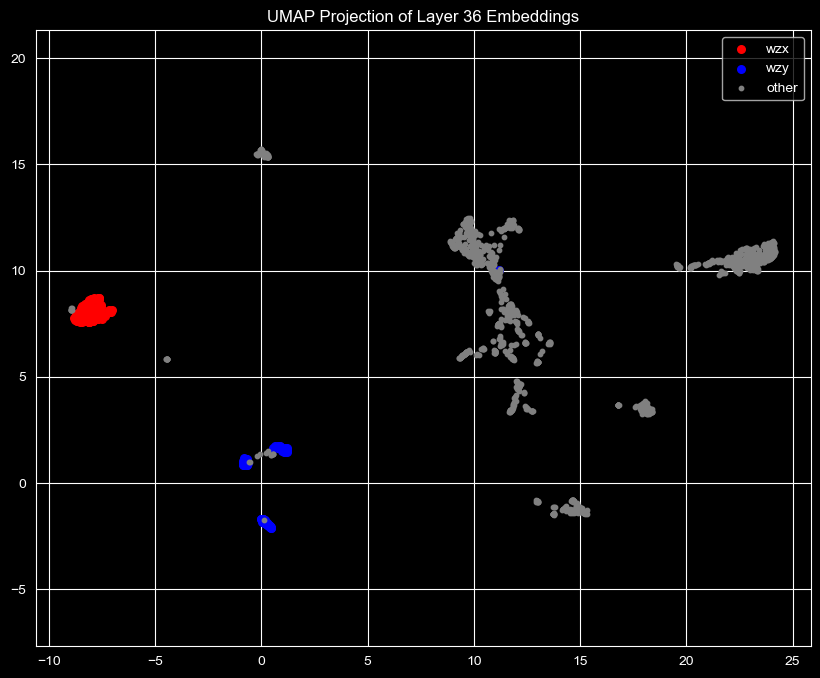

In [9]:
ids = embed36["id"]
label = pd.Series("other", index=ids.index, name="label")
label[ids.str.contains("wzx", case=False)] = "wzx"
label[ids.str.contains("wzy", case=False)] = "wzy"

colors = {"wzx": "red", "wzy": "blue", "other": "grey"}

plt.figure(figsize=(10, 8))
for name, color in colors.items():
    mask = label == name
    plt.scatter(embedding[mask, 0], embedding[mask, 1], c=color, label=name, s=10 if name == "other" else 30)
plt.gca().set_aspect('equal', 'datalim')
plt.legend()

plt.title('UMAP Projection of Layer 36 Embeddings')
plt.show()

In [10]:
import plotly.express as px

plot_df = pd.DataFrame({
    "UMAP1": embedding[:, 0],
    "UMAP2": embedding[:, 1],
    "id": ids.values,
    "label": label.values,
})

fig = px.scatter(
    plot_df,
    x="UMAP1",
    y="UMAP2",
    color="label",
    hover_name="id",
    color_discrete_map={"wzx": "red", "wzy": "blue", "other": "grey"},
    category_orders={"label": ["wzx", "wzy", "other"]},
    title="UMAP Projection of Layer 36 Embeddings",
)
fig.update_traces(marker={"size": 5})
fig.update_yaxes(scaleanchor="x", scaleratio=1)
fig.show()

In [11]:
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler

# Labels: Wzx / Wzy / Other from the protein IDs
y = pd.Series("Other", index=embed.index, name="label")
y[embed["id"].str.lower().str.contains("wzx")] = "Wzx"
y[embed["id"].str.lower().str.contains("wzy")] = "Wzy"

layers = sorted({int(c.split("_")[0].replace("layer", "")) for c in embed.columns if c.startswith("layer")})
print(f"{len(embed)} proteins, {y.value_counts().to_dict()}, layers {layers[0]}-{layers[-1]}")

# 80/20 stratified train/test split, kept fixed across all layers
X_train_idx, X_test_idx = train_test_split(
    embed.index, test_size=0.2, stratify=y, random_state=40
)
y_train, y_test = y.loc[X_train_idx], y.loc[X_test_idx]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
knn = KNeighborsClassifier(n_neighbors=5, metric="cosine")

cv_records = []
test_records = []

for layer in layers:
    X = filter_layer(embed, layer).select_dtypes(include="number")
    X_tr, X_te = X.loc[X_train_idx], X.loc[X_test_idx]

    scaler = StandardScaler().fit(X_tr)
    X_tr = scaler.transform(X_tr)
    X_te = scaler.transform(X_te)

    fold_scores = cross_val_score(knn, X_tr, y_train, cv=cv, scoring="f1_macro")
    for fold, score in enumerate(fold_scores, 1):
        cv_records.append({"layer": layer, "fold": fold, "f1_macro": score})

    knn.fit(X_tr, y_train)
    test_records.append(
        {"layer": layer, "f1_macro": f1_score(y_test, knn.predict(X_te), average="macro")}
    )

    print(f"layer {layer}: CV {fold_scores.mean():.3f} +/- {fold_scores.std():.3f}, test {test_records[-1]['f1_macro']:.3f}", flush=True)

cv_f1 = pd.DataFrame(cv_records)
test_f1 = pd.DataFrame(test_records)
summary = test_f1.merge(
    cv_f1.groupby("layer")["f1_macro"].agg(["mean", "std"]).reset_index(), on="layer"
)
summary

1634 proteins, {'Other': 1303, 'Wzx': 166, 'Wzy': 165}, layers 0-36
layer 0: CV 0.900 +/- 0.039, test 0.909
layer 1: CV 0.905 +/- 0.019, test 0.919
layer 2: CV 0.945 +/- 0.010, test 0.939
layer 3: CV 0.962 +/- 0.016, test 0.949
layer 4: CV 0.976 +/- 0.003, test 0.984
layer 5: CV 0.983 +/- 0.006, test 0.984
layer 6: CV 0.987 +/- 0.009, test 0.990
layer 7: CV 0.986 +/- 0.011, test 0.984
layer 8: CV 0.988 +/- 0.012, test 0.984
layer 9: CV 0.988 +/- 0.012, test 0.984
layer 10: CV 0.988 +/- 0.012, test 0.984
layer 11: CV 0.988 +/- 0.012, test 0.984
layer 12: CV 0.988 +/- 0.012, test 0.984
layer 13: CV 0.988 +/- 0.012, test 0.984
layer 14: CV 0.988 +/- 0.012, test 0.984
layer 15: CV 0.988 +/- 0.012, test 0.984
layer 16: CV 0.988 +/- 0.010, test 0.984
layer 17: CV 0.989 +/- 0.009, test 0.990
layer 18: CV 0.986 +/- 0.011, test 0.990
layer 19: CV 0.986 +/- 0.011, test 0.990
layer 20: CV 0.988 +/- 0.012, test 0.990
layer 21: CV 0.989 +/- 0.013, test 0.990
layer 22: CV 0.989 +/- 0.013, test 0.990

,layer,f1_macro,mean,std
0,0,0.909424,0.899928,0.043288
1,1,0.919427,0.905471,0.021179
2,2,0.939016,0.944588,0.011331
3,3,0.949104,0.961708,0.018160
4,4,0.984284,0.976474,0.003806
5,5,0.984284,0.983345,0.006287
6,6,0.989897,0.987460,0.010406
7,7,0.984428,0.986211,0.012837
8,8,0.984428,0.987585,0.013177
9,9,0.984428,0.987585,0.013177


In [20]:
embed[embed.index.isin(X_test_idx)].id

7            NZ_CP044311.1|CAOCEE_001561
17           NZ_CP044311.1|CAOCEE_001549
22           NZ_AP027258.1|CAOCEE_000870
25           NZ_AP027258.1|CAOCEE_000866
33           NZ_CP100876.1|CAOCEE_000486
                      ...               
1676      ecoh~~~wzy-O80~~~AB812032.1~~~
1677      ecoh~~~wzy-O81~~~AB812033.1~~~
1678      ecoh~~~wzy-O82~~~AB812034.1~~~
1679      ecoh~~~wzy-O83~~~AB812035.1~~~
1690    ecoh~~~wzy-OgN31~~~LC125932.1~~~
Name: id, Length: 327, dtype: str

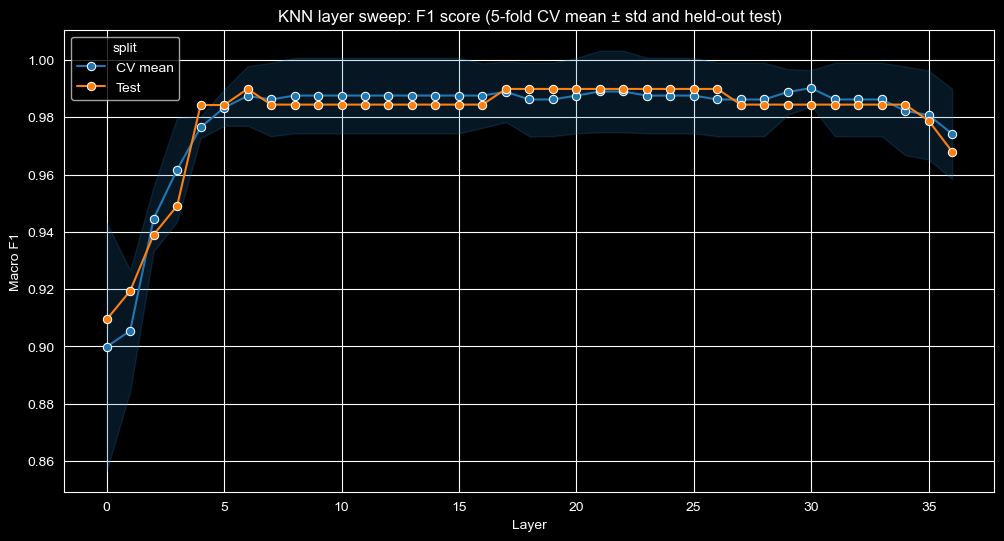

In [12]:
import seaborn as sns

plot_df = summary.rename(columns={"mean": "CV mean", "f1_macro": "Test"})
plot_df = plot_df.melt(
    id_vars="layer", value_vars=["CV mean", "Test"], var_name="split", value_name="f1_macro"
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=plot_df,
    x="layer",
    y="f1_macro",
    hue="split",
    palette={"CV mean": "tab:blue", "Test": "tab:orange"},
    marker="o",
    ax=ax,
)
ax.fill_between(
    summary["layer"],
    summary["mean"] - summary["std"],
    summary["mean"] + summary["std"],
    alpha=0.2,
    color="tab:blue",
    label="CV ± std",
)
ax.set_xlabel("Layer")
ax.set_ylabel("Macro F1")
ax.set_title("KNN layer sweep: F1 score (5-fold CV mean ± std and held-out test)")
plt.show()

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder



# Encode labels as integers; classes_ maps back to Wzx / Wzy / Other
le = LabelEncoder().fit(y_train)
y_train_enc, y_test_enc = le.transform(y_train), le.transform(y_test)

models = {
    "knn": KNeighborsClassifier(n_neighbors=5, metric="cosine"),
    "random_forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "svm": SVC(kernel="rbf", C=10, random_state=42),
    #"mlp": MLPClassifier(
        #hidden_layer_sizes=(256,), max_iter=300, random_state=42, early_stopping=True
    #),
}

cv_records_multi = []
test_records_multi = []

for layer in layers:
    X = filter_layer(embed, layer).select_dtypes(include="number")
    X_tr, X_te = X.loc[X_train_idx], X.loc[X_test_idx]

    scaler = StandardScaler().fit(X_tr)
    X_tr = scaler.transform(X_tr)
    X_te = scaler.transform(X_te)

    for name, model in models.items():
        fold_scores = cross_val_score(model, X_tr, y_train_enc, cv=cv, scoring="f1_macro")
        for fold, score in enumerate(fold_scores, 1):
            cv_records_multi.append({"layer": layer, "model": name, "fold": fold, "f1_macro": score})

        model.fit(X_tr, y_train_enc)
        test_records_multi.append(
            {"layer": layer, "model": name, "f1_macro": f1_score(y_test_enc, model.predict(X_te), average="macro")}
        )

    _layer_cv = pd.DataFrame(cv_records_multi)
    _layer_cv = _layer_cv[_layer_cv["layer"] == layer].groupby("model")["f1_macro"].mean()
    _layer_test = {r["model"]: r["f1_macro"] for r in test_records_multi if r["layer"] == layer}
    per_model = " | ".join(
        f"{name}: cv {_layer_cv[name]:.3f} test {_layer_test[name]:.3f}"
        for name in models
    )
    print(f"layer {layer}: {per_model}", flush=True)

cv_f1_multi = pd.DataFrame(cv_records_multi)
test_f1_multi = pd.DataFrame(test_records_multi)
summary_multi = test_f1_multi.merge(
    cv_f1_multi.groupby(["layer", "model"])["f1_macro"].agg(cv_mean="mean", cv_std="std").reset_index(),
    on=["layer", "model"],
)
summary_multi

layer 0: knn: cv 0.900 test 0.909 | random_forest: cv 0.898 test 0.890 | svm: cv 0.924 test 0.914
layer 1: knn: cv 0.905 test 0.919 | random_forest: cv 0.905 test 0.915 | svm: cv 0.951 test 0.949
layer 2: knn: cv 0.945 test 0.939 | random_forest: cv 0.948 test 0.929 | svm: cv 0.983 test 0.960
layer 3: knn: cv 0.962 test 0.949 | random_forest: cv 0.976 test 0.954 | svm: cv 0.993 test 0.970
layer 4: knn: cv 0.976 test 0.984 | random_forest: cv 0.981 test 0.984 | svm: cv 0.989 test 0.990
layer 5: knn: cv 0.983 test 0.984 | random_forest: cv 0.984 test 0.990 | svm: cv 0.996 test 0.990
layer 6: knn: cv 0.987 test 0.990 | random_forest: cv 0.993 test 0.990 | svm: cv 0.994 test 0.990
layer 7: knn: cv 0.986 test 0.984 | random_forest: cv 0.996 test 0.990 | svm: cv 0.994 test 0.990
layer 8: knn: cv 0.988 test 0.984 | random_forest: cv 0.994 test 0.990 | svm: cv 0.994 test 0.990
layer 9: knn: cv 0.988 test 0.984 | random_forest: cv 0.994 test 0.990 | svm: cv 0.994 test 0.990
layer 10: knn: cv 0.

,layer,model,f1_macro,cv_mean,cv_std
0,0,knn,0.909424,0.899928,0.043288
1,0,random_forest,0.890315,0.898435,0.013852
2,0,svm,0.914180,0.924327,0.026428
3,1,knn,0.919427,0.905471,0.021179
4,1,random_forest,0.914740,0.904554,0.018746
...,...,...,...,...,...
106,35,random_forest,0.989897,0.994275,0.005885
107,35,svm,0.984428,0.992947,0.004787
108,36,knn,0.968014,0.974217,0.015767
109,36,random_forest,0.989897,0.988906,0.014072


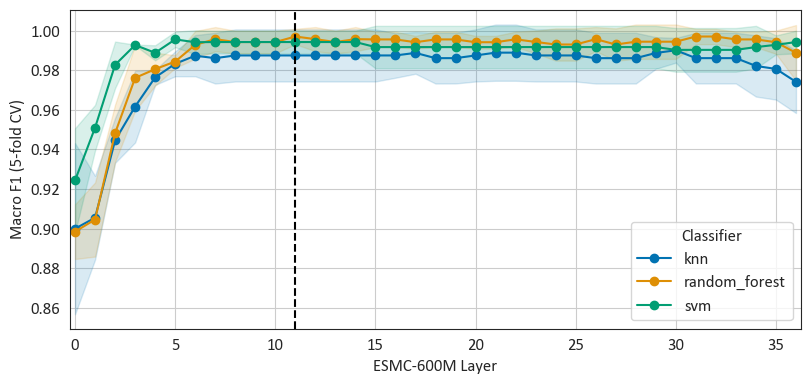

In [131]:
sns.set_style("white")
palette = dict(
    zip(
        summary_multi["model"].unique(),
        sns.color_palette("colorblind", n_colors=summary_multi["model"].nunique()),
    )
)

with plt.rc_context({
    "font.family": "Calibri",
    "font.size": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 12,
    "pdf.fonttype": 42,
}):
    fig, ax = plt.subplots(figsize=(8.27, 4))
    for model, group in summary_multi.groupby("model"):
        group = group.sort_values("layer")
        ax.plot(group["layer"], group["cv_mean"], label=model, color=palette[model], marker="o")
        ax.fill_between(
            group["layer"],
            group["cv_mean"] - group["cv_std"],
            group["cv_mean"] + group["cv_std"],
            color=palette[model],
            alpha=0.15,
        )
    ax.set_xlabel("ESMC-600M Layer", fontsize=12)
    ax.set_ylabel("Macro F1 (5-fold CV)", fontsize=12)
    #ax.set_title("Classifier comparison across ESMC layers (mean ± std of CV folds)")
    ax.legend(title="Classifier", fontsize=12)
    ax.axvline(x=11, color="k", linestyle="--", label="CV mean")
    ax.set_xlim(xmin=-0.25, xmax=36.25)
    ax.grid()
    plt.tight_layout()
    plt.savefig("figures/layer_sweep.pdf", bbox_inches="tight", format="pdf")
    plt.show()

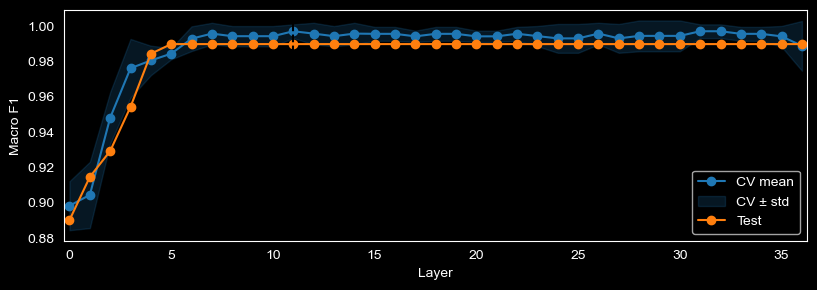

In [14]:
rf = summary_multi[summary_multi["model"] == "random_forest"].sort_values("layer")
rf_test = test_f1_multi[test_f1_multi["model"] == "random_forest"].sort_values("layer")["f1_macro"].values

fig, ax = plt.subplots(figsize=(8.27, 3))
ax.plot(rf["layer"], rf["cv_mean"], label="CV mean", color="tab:blue", marker="o")
ax.fill_between(
    rf["layer"],
    rf["cv_mean"] - rf["cv_std"],
    rf["cv_mean"] + rf["cv_std"],
    color="tab:blue",
    alpha=0.2,
    label="CV ± std",
)
ax.plot(rf["layer"], rf_test, label="Test", color="tab:orange", marker="o")
ax.set_xlabel("Layer")
ax.set_ylabel("Macro F1")
#ax.set_title("Random Forest: CV mean ± std and held-out test F1 per layer")
ax.legend()
ax.grid()
ax.axvline(x=11, color="k", linestyle="--", label="CV mean")
ax.set_xlim(xmin=-0.25, xmax=36.25)
plt.tight_layout()
plt.show()

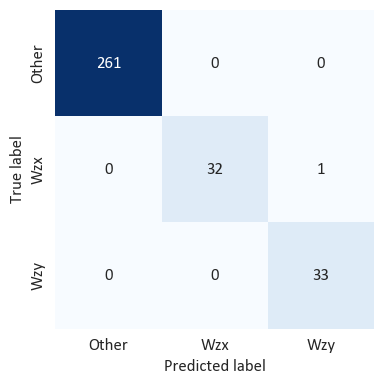

              precision    recall  f1-score   support

       Other       1.00      1.00      1.00       261
         Wzx       1.00      0.97      0.98        33
         Wzy       0.97      1.00      0.99        33

    accuracy                           1.00       327
   macro avg       0.99      0.99      0.99       327
weighted avg       1.00      1.00      1.00       327



In [15]:
# Refit the RF on layer 9 and show the confusion matrix on the held-out test split
from sklearn.metrics import confusion_matrix, classification_report
sns.set_style("white")
layer_cm = 11
X_cm = filter_layer(embed, layer_cm).select_dtypes(include="number")
X_tr_cm, X_te_cm = X_cm.loc[X_train_idx], X_cm.loc[X_test_idx]

scaler_cm = StandardScaler().fit(X_tr_cm)
X_tr_cm, X_te_cm = scaler_cm.transform(X_tr_cm), scaler_cm.transform(X_te_cm)

rf_cm = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_cm.fit(X_tr_cm, y_train_enc)
y_pred_cm = rf_cm.predict(X_te_cm)

cm = confusion_matrix(y_test_enc, y_pred_cm)
cm_df = pd.DataFrame(cm, index=le.classes_, columns=le.classes_)

with plt.rc_context({
    "font.family": "Calibri",
    "font.size": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "pdf.fonttype": 42,
}):
    fig, ax = plt.subplots(figsize=(4.135, 4))
    sns.heatmap(
        cm_df,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        square=True,
        annot_kws={"size": 12},
        ax=ax,
    )
    ax.set_xlabel("Predicted label", fontsize=12)
    ax.set_ylabel("True label", fontsize=12)
    #ax.set_title(f"Random Forest confusion matrix, layer {layer_cm} (test split)")
    plt.tight_layout()
    plt.savefig("figures/rf_cm.pdf", format="pdf", bbox_inches="tight")
    plt.show()
print(classification_report(y_test_enc, y_pred_cm, target_names=le.classes_))
# Bundle the fitted scaler and RF into one pipeline so the scaling is exported too
from sklearn.pipeline import Pipeline

rf_cm_pipeline = Pipeline([("scaler", scaler_cm), ("rf", rf_cm)])

In [19]:
import joblib

# Export the trained model to a file (pipeline contains the fitted scaler + RF,
# plus the label encoder to decode the predicted class labels)
joblib.dump(
    {"pipeline": rf_cm_pipeline, "label_encoder": le},
    "wzx-wzy-rf.joblib",
)

['wzx-wzy-rf.joblib']

               Feature  Importance
760    layer11_dim_760    0.029976
18      layer11_dim_18    0.027740
280    layer11_dim_280    0.023897
530    layer11_dim_530    0.023368
426    layer11_dim_426    0.020597
...                ...         ...
711    layer11_dim_711    0.000000
281    layer11_dim_281    0.000000
714    layer11_dim_714    0.000000
279    layer11_dim_279    0.000000
1151  layer11_dim_1151    0.000000

[1152 rows x 2 columns]


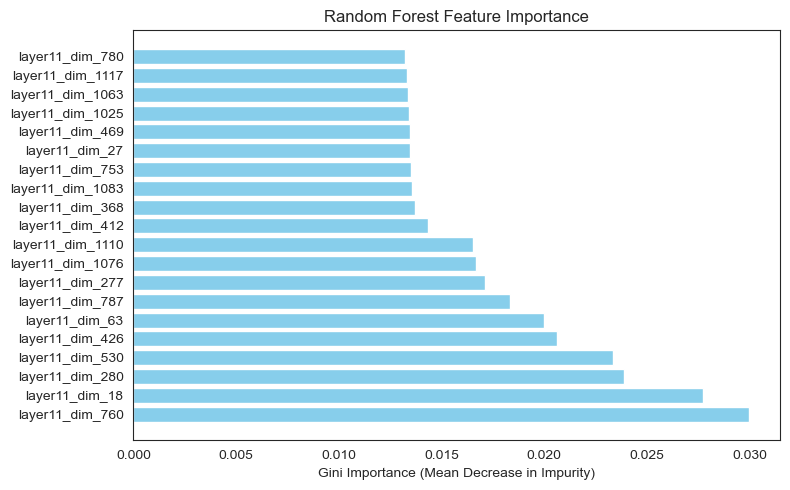

In [17]:
importances = rf_cm.feature_importances_

# 4. Organize into a Pandas DataFrame
feature_importance_df = pd.DataFrame(
    {"Feature": X_cm.columns, "Importance": importances}
).sort_values(by="Importance", ascending=False)

print(feature_importance_df)

# 5. Plot the importances
plt.figure(figsize=(8, 5))
plt.barh(
    feature_importance_df["Feature"][0:20],
    feature_importance_df["Importance"][0:20],
    color="skyblue",
)
plt.xlabel("Gini Importance (Mean Decrease in Impurity)")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

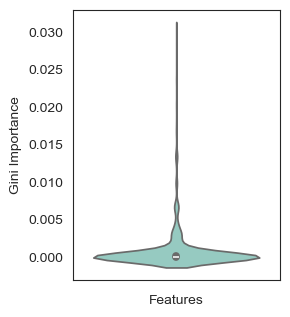

In [103]:
plt.figure(figsize=(3, 3))
sns.violinplot(feature_importance_df, y="Importance")
plt.tight_layout()
plt.ylabel("Gini Importance")
plt.xlabel("Features")
plt.show()

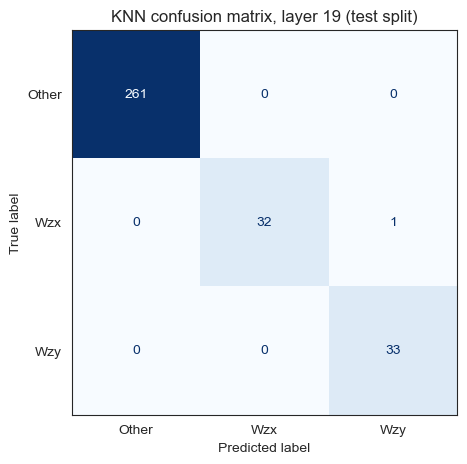

In [46]:
# Refit the KNN on layer 19 and show the confusion matrix on the held-out test split
layer_cm = 19
X_cm = filter_layer(embed, layer_cm).select_dtypes(include="number")
X_tr_cm, X_te_cm = X_cm.loc[X_train_idx], X_cm.loc[X_test_idx]

scaler_cm = StandardScaler().fit(X_tr_cm)
X_tr_cm, X_te_cm = scaler_cm.transform(X_tr_cm), scaler_cm.transform(X_te_cm)

knn_cm = KNeighborsClassifier(n_neighbors=5, metric="cosine")
knn_cm.fit(X_tr_cm, y_train_enc)
y_pred_cm = knn_cm.predict(X_te_cm)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_enc,
    y_pred_cm,
    display_labels=le.classes_,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title(f"KNN confusion matrix, layer {layer_cm} (test split)")
plt.show()

/Users/uqsmor23/miniconda3/envs/ECRefSeq_Oag_db/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


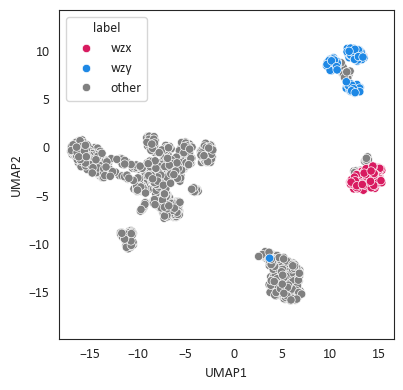

In [137]:
# Seaborn UMAP of layer 15 embeddings
#sns.set_style("white")
import matplotlib.pyplot as plt

# 1. Set the global font family to sans-serif and prioritize Calibri
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri'] + plt.rcParams['font.sans-serif']
embed15 = filter_layer(embed, 11)
ids15 = embed15["id"]
label15 = pd.Series("other", index=ids15.index, name="label")
label15[ids15.str.contains("wzx", case=False)] = "wzx"
label15[ids15.str.contains("wzy", case=False)] = "wzy"

X15 = embed15.select_dtypes(include="number").values
X15_scaled = StandardScaler().fit_transform(X15)
reducer15 = umap.UMAP(n_neighbors=160, min_dist=0.7, random_state=42, metric="cosine")
embedding15 = reducer15.fit_transform(X15_scaled)

umap15_df = pd.DataFrame({
    "UMAP1": embedding15[:, 0],
    "UMAP2": embedding15[:, 1],
    "id": ids15.values,
    "label": label15.values,
})

fig, ax = plt.subplots(figsize=(4.135, 4))
sns.scatterplot(
    data=umap15_df,
    x="UMAP1",
    y="UMAP2",
    hue="label",
    hue_order=["wzx", "wzy", "other"],
    palette={"wzx": "#D81B60", "wzy": "#1E88E5", "other": "grey"},
    ax=ax,
)
ax.set_aspect("equal", "datalim")
#ax.set_title("UMAP Projection of Layer 15 Embeddings")
plt.tight_layout()
plt.savefig("figures/umap9.pdf", bbox_inches="tight", format="pdf")
plt.show()

layer 0: 0.0147
layer 1: 0.0013
layer 2: 0.0011
layer 3: 0.0018
layer 4: 0.0046
layer 5: 0.0203
layer 6: 0.0440
layer 7: 0.0693
layer 8: 0.1638
layer 9: 0.0938
layer 10: 0.0637
layer 11: 0.0415
layer 12: 0.0397
layer 13: 0.0407
layer 14: 0.0606
layer 15: 0.0578
layer 16: 0.0508
layer 17: 0.0269
layer 18: 0.0089
layer 19: 0.0092
layer 20: 0.0304
layer 21: 0.0443
layer 22: 0.0577
layer 23: 0.0668
layer 24: 0.0869
layer 25: 0.1079
layer 26: 0.1121
layer 27: 0.1159
layer 28: 0.1262
layer 29: 0.1384
layer 30: 0.1267
layer 31: 0.1258
layer 32: 0.1110
layer 33: 0.1137
layer 34: 0.1463
layer 35: 0.1094
layer 36: 0.0641


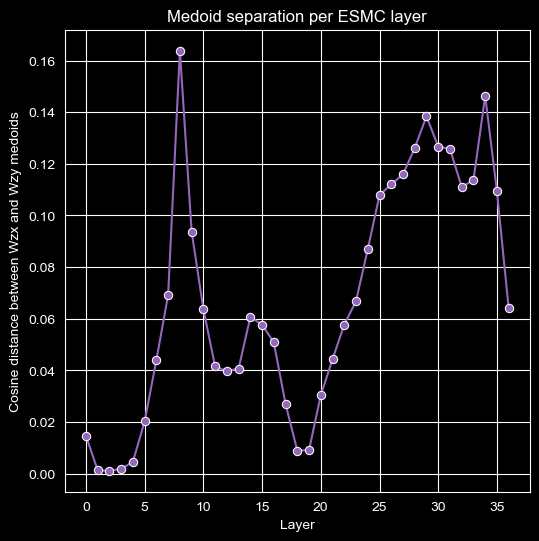

In [21]:
# Medoid separation sweep: per layer, compute the Wzx and Wzy medoids (embedding space)
# and the cosine distance between them.
from sklearn.metrics import pairwise_distances

# cosine-normalise each layer's embeddings once; medoid = point with min total distance
medoid_records = []
mask_wzx = y == "Wzx"
mask_wzy = y == "Wzy"

for layer in layers:
    X_layer = filter_layer(embed, layer).select_dtypes(include="number")
    X_norm = X_layer.divide(np.linalg.norm(X_layer, axis=1, keepdims=True), axis=0)

    medoids = {}
    for name, mask in (("Wzx", mask_wzx), ("Wzy", mask_wzy)):
        pts = X_norm.loc[mask]
        dists = pairwise_distances(pts, metric="cosine")
        medoids[name] = pts.iloc[dists.sum(axis=1).argmin()]

    d = 1 - float(np.dot(medoids["Wzx"], medoids["Wzy"]))
    medoid_records.append({"layer": layer, "wzx_wzy_cosine_distance": d})
    print(f"layer {layer}: {d:.4f}", flush=True)

medoid_dist = pd.DataFrame(medoid_records)

fig, ax = plt.subplots(figsize=(6, 6))
sns.lineplot(data=medoid_dist, x="layer", y="wzx_wzy_cosine_distance", marker="o", color="tab:purple", ax=ax)
ax.set_xlabel("Layer")
ax.set_ylabel("Cosine distance between Wzx and Wzy medoids")
ax.set_title("Medoid separation per ESMC layer")
plt.show()

k=2: inertia 1483597.2
k=3: inertia 1321226.1
k=4: inertia 1171407.1
k=5: inertia 1042476.6
k=6: inertia 968762.2
k=7: inertia 894023.5
k=8: inertia 842866.0
k=9: inertia 792230.0
k=10: inertia 762719.6
k=11: inertia 724015.5
k=12: inertia 695906.8
k=13: inertia 674267.7
k=14: inertia 654393.3
k=15: inertia 636833.1


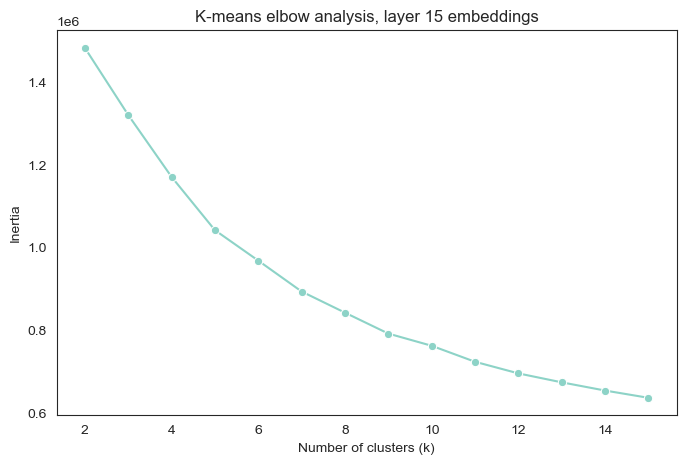

In [96]:
# K-means elbow analysis on layer 15 embeddings
from sklearn.cluster import KMeans

ks = range(2, 16)
inertias = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X15_scaled)
    inertias.append({"k": k, "inertia": km.inertia_})
    print(f"k={k}: inertia {km.inertia_:.1f}", flush=True)

elbow_df = pd.DataFrame(inertias)

fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(data=elbow_df, x="k", y="inertia", marker="o", ax=ax)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia")
ax.set_title("K-means elbow analysis, layer 15 embeddings")
plt.show()

In [97]:
# Unsupervised K-means (k=7) on layer 15 embeddings, cluster composition by true label
k7 = KMeans(n_clusters=7, random_state=42, n_init=10)
cluster = k7.fit_predict(X15_scaled)

comp = (
    pd.DataFrame({"cluster": cluster, "label": label15.values})
    .groupby(["cluster", "label"])
    .size()
    .unstack(fill_value=0)
)
comp["total"] = comp.sum(axis=1)
comp.loc["total"] = comp.sum()
comp

label,other,wzx,wzy,total
cluster,,,,
0,336,0,1,337
1,425,0,0,425
2,15,165,0,180
3,9,1,164,174
4,122,0,0,122
5,321,0,0,321
6,75,0,0,75
total,1303,166,165,1634


In [98]:
# K-means (k=3) on Wzy embeddings only, layer 15
mask_wzy_only = label15 == "wzy"
X_wzy = X15_scaled[mask_wzy_only.values]

km_wzy = KMeans(n_clusters=3, random_state=42, n_init=10)
wzy_cluster = km_wzy.fit_predict(X_wzy)

wzy_comp = (
    pd.DataFrame({"cluster": wzy_cluster, "id": ids15[mask_wzy_only].values})
    .sort_values(["cluster", "id"])
    .set_index(["cluster", "id"])
)
wzy_sizes = pd.Series(wzy_cluster).value_counts().sort_index().rename("n_proteins")
wzy_sizes

0    49
1    56
2    60
Name: n_proteins, dtype: int64